### Test model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import os, sys, gc, time, warnings, pickle, psutil, random
from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
from lightgbm import early_stopping, log_evaluation
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split, GridSearchCV
import seaborn as sns
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# import pandas as pd

# # Giả sử bạn đã đọc 3 file csv thành 3 dataframe
# texas = pd.read_csv('texas.csv')
# cali = pd.read_csv('california.csv')
# wicosin = pd.read_csv('wicosin.csv')


# # Tính trung bình độ ẩm theo ngày cho từng bang
# texas = texas.groupby('day')['avg_rh'].mean().reset_index()
# cali = cali.groupby('day')['avg_rh'].mean().reset_index()
# wicosin = wicosin.groupby('day')['avg_rh'].mean().reset_index()

# # Thêm cột state_id cho từng dataframe
# texas['state_id'] = '1'
# cali['state_id'] = '2'
# wicosin['state_id'] = '3'

# # Đổi tên cột avg_rh thành huminity
# texas = texas.rename(columns={'avg_rh': 'huminity', 'day':'date'})
# cali = cali.rename(columns={'avg_rh': 'huminity', 'day':'date'})
# wicosin = wicosin.rename(columns={'avg_rh': 'huminity','day':'date'})


# # Gộp 3 dataframe lại với nhau, chọn đúng các cột cần thiết
# combined_df = pd.concat([texas[['date', 'state_id', 'huminity']],
#                          cali[['date', 'state_id', 'huminity']],
#                          wicosin[['date', 'state_id', 'huminity']]],
#                         ignore_index=True)

# print(combined_df)

# combined_df['date'] = pd.to_datetime(combined_df['date'])
# combined_df['state_id'] = combined_df['state_id'].astype('int')
# combined_df['date']
# merged_df = pd.merge(df, combined_df, on=['state_id', 'date'], how='left')

In [3]:
df = pd.read_parquet('../data/train_val.parquet')
print(df.head())

def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

df = downcast(df)

                   id  item_id  store_id  state_id  dept_id  cat_id     d  \
0  HOBBIES_1_001_CA_1     1438         1         1        4       2  1029   
1  HOBBIES_1_002_CA_1     1439         1         1        4       2  1029   
2  HOBBIES_1_003_CA_1     1440         1         1        4       2  1029   
3  HOBBIES_1_004_CA_1     1441         1         1        4       2  1029   
4  HOBBIES_1_005_CA_1     1442         1         1        4       2  1029   

   demand  lag_t7  rolling_mean_lag7_w7  ...  event_name_2  snap_CA  snap_TX  \
0     0.0     0.0              1.000000  ...             1        0        0   
1     0.0     1.0              0.142857  ...             1        0        0   
2     0.0     0.0              0.000000  ...             1        0        0   
3     3.0     0.0              1.142857  ...             1        0        0   
4     1.0     1.0              0.428571  ...             1        0        0   

   snap_WI sell_price  disaster_type  disaster_severity_

In [4]:
df.columns

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc', 'gold_price', 'huminity'],
      dtype='object')

In [5]:
df = df.drop(['date','disaster_type'],axis=1)

In [6]:
sample_submission = pd.read_csv('../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):
    
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x = prep_train(df, 1000 - 28)

del df
gc.collect()

['event_name_2', 'gold_price', 'lag_t7', 'lag_t28', 'rolling_mean_lag7_w28', 'disaster_severity_flag', 'snap_CA', 'month', 'rolling_mean_lag7_w7', 'flag_ufc', 'rolling_mean_lag28_w28', 'sell_price', 'item_id', 'snap_WI', 'dept_id', 'year', 'event_name_1', 'snap_TX', 'rolling_mean_lag28_w7', 'cat_id', 'wday', 'huminity', 'store_id', 'state_id']


42

c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\engine.py:177: UserWarning: Found `n_estimators` in params. Will use it instead of argument
  _log_warning(f"Found `{alias}` in params. Will use it instead of argument")


[LightGBM] [Info] Total Bins 2298
[LightGBM] [Info] Number of data points in the train set: 25053633, number of used features: 24
[LightGBM] [Info] Start training from score 0.206062
Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 2.64479
[200]	valid_0's rmse: 2.34361
[300]	valid_0's rmse: 2.25975
[400]	valid_0's rmse: 2.23302
[500]	valid_0's rmse: 2.22109
[600]	valid_0's rmse: 2.21369
[700]	valid_0's rmse: 2.20902
[800]	valid_0's rmse: 2.20456
[900]	valid_0's rmse: 2.20002
[1000]	valid_0's rmse: 2.19605
[1100]	valid_0's rmse: 2.19244
[1200]	valid_0's rmse: 2.18895
[1300]	valid_0's rmse: 2.18583
[1400]	valid_0's rmse: 2.1823
[1500]	valid_0's rmse: 2.17944
Did not meet early stopping. Best iteration is:
[1500]	valid_0's rmse: 2.17944


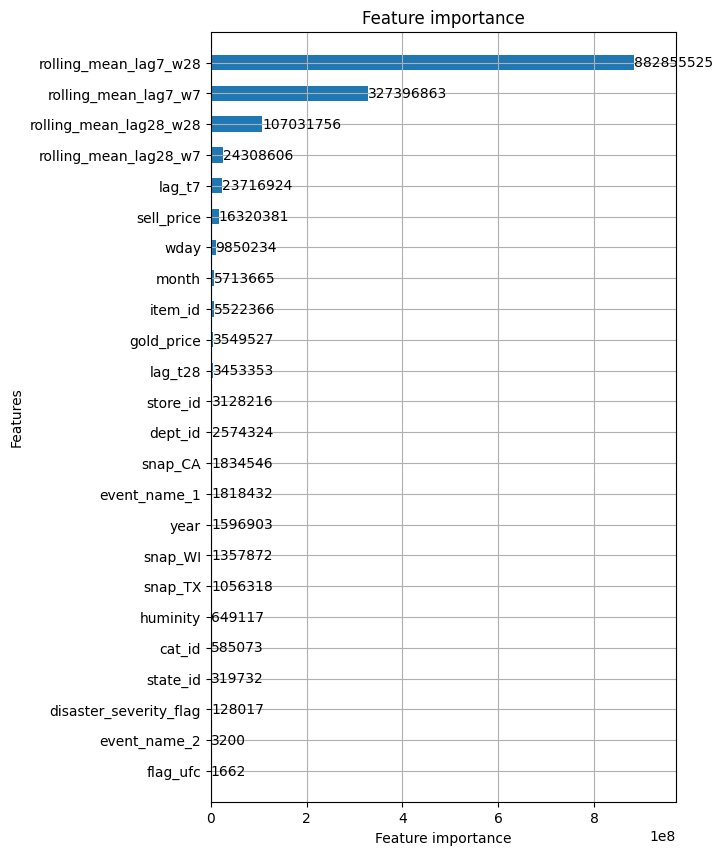

True

In [9]:
def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


fit = fit_model(train, valid,1500)
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="submission.csv")

In [8]:
del pred
gc.collect()

7129